In [1]:
from pathlib import Path

from dimelo import parse_bam
from dimelo import plot_enrichment_profile, plot_read_browser, plot_enrichment
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
import plotly.graph_objects as go

import config

In [2]:
# All direct-RNA inputs live under data/direct_rna/ (see "Direct RNA data" in the README)
direct_rna_dir = config.data_dir / "direct_rna"
direct_rna_raw_dir = direct_rna_dir / "raw"
direct_rna_processed_dir = direct_rna_dir / "processed"

# Custom hs1 (T2T-CHM13) + rDNA (chrR) reference
genome_file = direct_rna_raw_dir / "hs1-rDNA_v1.0.fa"
# Dorado 0.7.2 (rna004_130bps_sup@v5.0.0, m6A + pseU), spliced realignment to hs1-rDNA
rna_bam_file = direct_rna_processed_dir / "basecalled_m6A_pseU.splice.hs1-rDNA_v1.0.sorted.bam"
# Stop codons of high-confidence (NM_/NR_) RefSeq transcripts, from third_party_data.ipynb
stop_codon_bed_file = direct_rna_processed_dir / "hs1_stop_codons_high_confidence.bed"

figure_dir = config.figure_dir

In [3]:
# Genome-wide (chr1) + rDNA (chrR) pileup
# chr1_R_pileup, _ = parse_bam.pileup(
#     input_file=rna_bam_file,
#     output_name="chr1_R_pileup_spliced",
#     output_directory=direct_rna_processed_dir,
#     ref_genome=genome_file,
#     regions=["chr1:0-248_387_328","chrR:0-44837"],
#     motifs=["T,0,17802","A,0,a","DRACH,2,a","GTTC,2,17802","TSTAG,2,17802","TGTAG,2,17802","TGTAR,2,17802"],
#     thresh=0.98,
# )
chr1_R_pileup = direct_rna_processed_dir / "chr1_R_pileup_spliced" / "pileup.sorted.bed.gz"

# Pileup in windows around annotated stop codons
# stop_codon_pileup, _ = parse_bam.pileup(
#     input_file=rna_bam_file,
#     output_name="stop_codon_pileup_spliced",
#     output_directory=direct_rna_processed_dir,
#     ref_genome=genome_file,
#     regions=stop_codon_bed_file,
#     motifs=["T,0,17802","A,0,a","DRACH,2,a","GTTC,2,17802","TSTAG,2,17802"],
#     window_size=1500,
#     thresh=0.98,
# )
stop_codon_pileup = direct_rna_processed_dir / "stop_codon_pileup_spliced" / "pileup.sorted.bed.gz"

# Single-read extraction over the rDNA repeat
# rrna_extract, _ = parse_bam.extract(
#     input_file=rna_bam_file,
#     output_name="rDNA_rrnas",
#     output_directory=direct_rna_processed_dir,
#     ref_genome=genome_file,
#     regions="chrR:0-44837",
#     motifs=["T,0,17802","A,0,a","DRACH,2,a","GTTC,2,17802","TSTAG,2,17802"],
# )
rrna_extract = direct_rna_processed_dir / "rDNA_rrnas" / "reads.combined_basemods.h5"

Loading data:   0%|          | 0/249 [00:00<?, ?it/s]

Loading data:   0%|          | 0/249 [00:00<?, ?it/s]

Loading data:   0%|          | 0/249 [00:00<?, ?it/s]

Loading data:   0%|          | 0/249 [00:00<?, ?it/s]

Loading data:   0%|          | 0/249 [00:00<?, ?it/s]

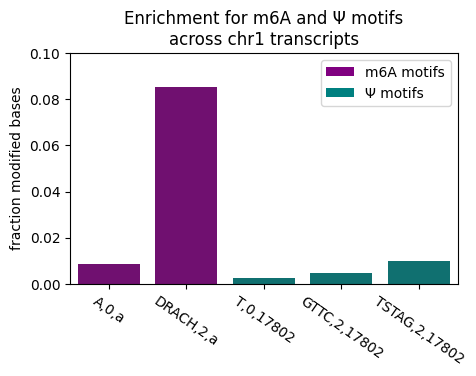

Loading data:   0%|          | 0/1 [00:00<?, ?it/s]

Loading data:   0%|          | 0/1 [00:00<?, ?it/s]

Loading data:   0%|          | 0/1 [00:00<?, ?it/s]

Loading data:   0%|          | 0/1 [00:00<?, ?it/s]

Loading data:   0%|          | 0/1 [00:00<?, ?it/s]

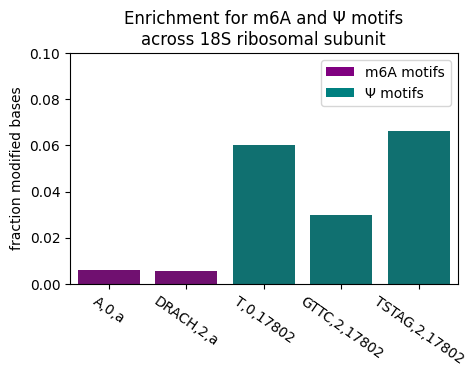

In [4]:
RRNA_18S = "chrR:12996-14864"
names_list = ["chr1_transcripts", "18S ribosomal subunit"]
regions_list = ["chr1:0-248_387_328", [RRNA_18S]]
for name,region in zip(names_list,regions_list):
    fig, ax = plt.subplots(figsize=(5,3))
    plot_enrichment.by_modification(
        mod_file_name=chr1_R_pileup,
        regions=region,
        motifs=["A,0,a","DRACH,2,a", "T,0,17802","GTTC,2,17802","TSTAG,2,17802"],
        ax=ax,
        palette={
            "A,0,a":"purple",
            "DRACH,2,a":"purple",
            "T,0,17802":"teal",
            "GTTC,2,17802":"teal",
            "TSTAG,2,17802":"teal",
            "TGTAR,2,17802":"teal",
        }
    )
    plt.title(f"Enrichment for m6A and Ψ motifs\nacross {name.replace('_',' ')}")
    plt.xticks(rotation=325)

    legend_elements = [
        Patch(facecolor='purple', label='m6A motifs'),
        Patch(facecolor='teal', label='Ψ motifs')
    ]
    ax.legend(handles=legend_elements)

    plt.ylim(0.0,0.1)
    fig.savefig(figure_dir / f"m6A_pseU_enrichment_across_{name}.svg", format="svg", bbox_inches='tight', dpi=300)
    plt.show()

Loading data:   0%|          | 0/66619 [00:00<?, ?it/s]

Loading data:   0%|          | 0/66619 [00:00<?, ?it/s]

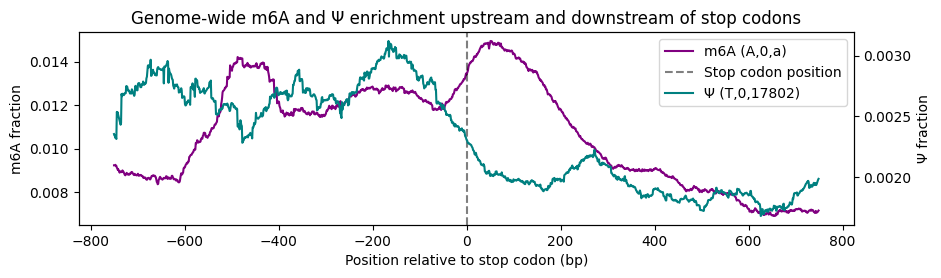

In [5]:
fig, ax1 = plt.subplots(figsize=(10,2.5))
ax2 = ax1.twinx()
plot_enrichment_profile.plot_enrichment_profile(
    mod_file_names=[stop_codon_pileup],
    motifs=["A,0,a"],
    regions_list=[stop_codon_bed_file],
    sample_names=["m6A (A,0,a)"],
    window_size=750,
    smooth_window=100,
    regions_5to3prime = True,
    palette = {
        "m6A (A,0,a)": "purple",
    },
    ax=ax1,
)
ax1.set_ylabel("m6A fraction")
plot_enrichment_profile.plot_enrichment_profile(
    mod_file_names=[stop_codon_pileup],
    motifs=["T,0,17802"],
    regions_list=[stop_codon_bed_file],
    sample_names=["Ψ (T,0,17802)"],
    window_size=750,
    smooth_window=100,
    regions_5to3prime = True,
    ax=ax2,
    palette = {
        "Ψ (T,0,17802)": "teal",
    },
)
ax2.set_ylabel("Ψ fraction")
ax1.axvline(x=0, color='black', linestyle='--', alpha=0.5, label='Stop codon position')
ax1.set_xlabel("Position relative to stop codon (bp)")
# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='best')

# Remove the legend from ax2 if it exists
if ax2.get_legend() is not None:
    ax2.get_legend().remove()

plt.title("Genome-wide m6A and Ψ enrichment upstream and downstream of stop codons")
fig.savefig(figure_dir / "m6A_pseU_profile_around_stop_codons.svg", format="svg", bbox_inches='tight', dpi=300)

In [6]:
fig = plot_read_browser.plot_read_browser(
    mod_file_name=rrna_extract,
    # region = f"chrR:{12996+10}-{14864-00}",
    region = f"chrR:{12996-2000}-{14864+2000}",
    # motifs=["HRT,2,17802","DRACH,2,a"],
    motifs = ["A,0,a","T,0,17802"],
    sort_by=("read_length","desc"),
    thresh=0.9,
    # span_full_window=True,
    # size=2,
    colorscales={
        "GTTC,2,17802":["white","teal"],
        "TSTAG,2,17802":["white","green"],
        "DRACH,2,a":["white","purple"],
        "T,0,17802":["white","teal"],
        "A,0,a":["white","purple"],
        },
)
fig.update_layout(
    width=900,# these values are in pixels
    height=300,    
    title={
        'text': "dRNA reads aligned to 18S rRNA gene body and flanking regions",
        'x': 0.5,
        'xanchor': 'center',
        'y': 0.75,  # Adjust the vertical position of the title
        'yanchor': 'top',
        'pad': {'b': 10} 
    },
    xaxis_title='chrR coordinates, hs1-rDNA v1.0',
    yaxis_title='reads',
    font=dict(color='black')
)
# Define your regions (from the BED file data you provided)
regions = [
    {'start': 9339, 'end': 12995, 'label': "5' ETS"},
    {'start': 12996, 'end': 14864, 'label': '18S'},
    {'start': 14865, 'end': 15934, 'label': 'ITS1'},
    {'start': 15935, 'end': 16091, 'label': '5.8S'},
    {'start': 16092, 'end': 17258, 'label': 'ITS2'},
]

# Add a horizontal line spanning all regions at the top
fig.add_shape(
    type="line",
    x0=regions[0]['start'],
    x1=regions[-1]['end'],
    y0=1.02,  # Just above the plot
    y1=1.02,
    yref="paper",
    line=dict(color="black", width=2),
)

# Add vertical tick marks at region boundaries - much taller
for i, region in enumerate(regions):
    # Tick at start of region
    fig.add_shape(
        type="line",
        x0=region['start'],
        x1=region['start'],
        y0=1.02,
        y1=1.09,  # Much taller tick (increased from 0.02 to 0.04 height)
        yref="paper",
        line=dict(color="black", width=2),
    )
    # Tick at end of last region
    if i == len(regions) - 1:
        fig.add_shape(
            type="line",
            x0=region['end'],
            x1=region['end'],
            y0=1.02,
            y1=1.09,
            yref="paper",
            line=dict(color="black", width=2),
        )

# Add text annotations above the line
for region in regions:
    mid_point = (region['start'] + region['end']) / 2
    fig.add_annotation(
        x=mid_point,
        y=1.08,  # Above the ticks
        yref="paper",
        text=region['label'],
        showarrow=False,
        font=dict(size=11, color="black", family="Arial"),
        xanchor="center",
        yanchor="bottom"
    )

# Add label on the left indicating these are annotations
fig.add_annotation(
    x=0,
    xref="paper",
    y=1.055,  # Centered vertically with the annotation track
    yref="paper",
    text="rRNA<br>annotations",
    showarrow=False,
    font=dict(size=11, color="black", family="Arial"),
    xanchor="right",
    yanchor="middle",
    xshift=-10  # Add a bit of space from the left edge
)

# Update layout to make room at the top
fig.update_layout(
    margin=dict(t=120),  # Increase top margin
)

fig.write_image(figure_dir / "18SRNA_flanking_read_browser.svg", format="svg")
display(fig)

In [7]:
fig = plot_read_browser.plot_read_browser(
    mod_file_name=rrna_extract,
    region = f"chrR:{12996+10}-{14864-00}",
    # motifs=["HRT,2,17802","DRACH,2,a"],
    motifs = ["A,0,a","T,0,17802"],
    sort_by="read_end",
    thresh=0.9,
    width=0.5,
    span_full_window=True,
    # size=2,
    colorscales={
        "GTTC,2,17802":["white","teal"],
        "TSTAG,2,17802":["white","green"],
        "DRACH,2,a":["white","purple"],
        "T,0,17802":["white","teal"],
        "A,0,a":["white","purple"],
        },
)
fig.update_layout(
    width=900,# these values are in pixels
    height=350,    
    title={
        'text': "dRNA reads spanning the entire 18S rRNA gene body",
        'x': 0.5,
        'xanchor': 'center',
        'y': 0.8,  # Adjust the vertical position of the title
        'yanchor': 'top',
        'pad': {'b': 10} 
    },
    xaxis_title='chrR coordinate, hs1-rDNA v1.0',
    yaxis_title='reads',
    font=dict(color='black')
)
fig.write_image(figure_dir / "18SRNA_spanning_read_browser.svg", format="svg")
display(fig)